In [3]:
import mne
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


mne.set_log_level('ERROR')

In [4]:
%matplotlib inline
import warnings
warnings.filterwarnings('ignore')

In [5]:
raw_train_1 = mne.io.read_raw_gdf("../datasets/A01T.gdf")
raw_eval_1 = mne.io.read_raw_gdf("../datasets/A01E.gdf")

## Imports

In [6]:
from sklearn.covariance import OAS
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.manifold import TSNE
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
from scipy.cluster.hierarchy import linkage, dendrogram

## Epoching (left vs right)

In [7]:
def prepare(raw):
    raw.load_data()
    raw.pick([c for c in raw.ch_names if not c.startswith('EOG')])
    raw.filter(8, 30, fir_design='firwin')                      # mu + beta
    ann = raw.annotations                                       # drop trials flagged as artifacts (1023)
    desc = np.where(ann.description == '1023', 'BAD_artifact', ann.description)
    raw.set_annotations(mne.Annotations(ann.onset, ann.duration, desc, orig_time=ann.orig_time))
    events, _ = mne.events_from_annotations(raw, event_id={'769': 1, '770': 2})   # 1=left, 2=right
    return mne.Epochs(raw, events, tmin=0.5, tmax=2.5, baseline=None,
                      preload=True, reject_by_annotation=True)

epochs = prepare(raw_train_1)
X = epochs.get_data()              # (trials, channels, samples)
y_true = epochs.events[:, 2]       # used for evaluation only, never for fitting
print(X.shape, np.bincount(y_true)[1:])

(138, 22, 501) [69 69]


## Unsupervised feature extraction (covariance → tangent space → PCA)

In [8]:
def symfun(C, f):
    w, v = np.linalg.eigh(C)
    return (v * f(w)) @ v.T

covs = np.array([OAS().fit(x.T).covariance_ for x in X])                     
ref = symfun(np.mean([symfun(c, np.log) for c in covs], axis=0), np.exp)     
W = symfun(ref, lambda w: w ** -0.5)
iu = np.triu_indices(covs.shape[1])
coef = np.where(iu[0] == iu[1], 1.0, np.sqrt(2))
F = np.array([symfun(W @ c @ W, np.log)[iu] * coef for c in covs])           

Fs = StandardScaler().fit_transform(F)
pca = PCA(n_components=10, random_state=0)
Z = pca.fit_transform(Fs)
print(F.shape, '->', Z.shape, '| explained var:', pca.explained_variance_ratio_.sum().round(3))

(138, 253) -> (138, 10) | explained var: 0.294


## K-Means: elbow curve

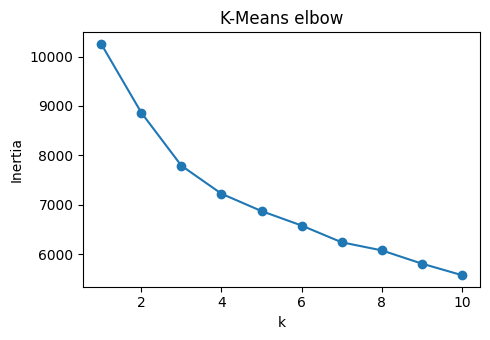

In [9]:
ks = range(1, 11)
inertia = [KMeans(k, n_init=10, random_state=0).fit(Z).inertia_ for k in ks]

plt.figure(figsize=(5, 3.5))
plt.plot(ks, inertia, 'o-')
plt.xlabel('k'); plt.ylabel('Inertia'); plt.title('K-Means elbow')
plt.tight_layout(); plt.show()

K = 2   # left vs right

In [10]:
labels = {}
labels['KMeans'] = KMeans(K, n_init=20, random_state=0).fit_predict(Z)

## Hierarchical: dendrograms and linkage comparison

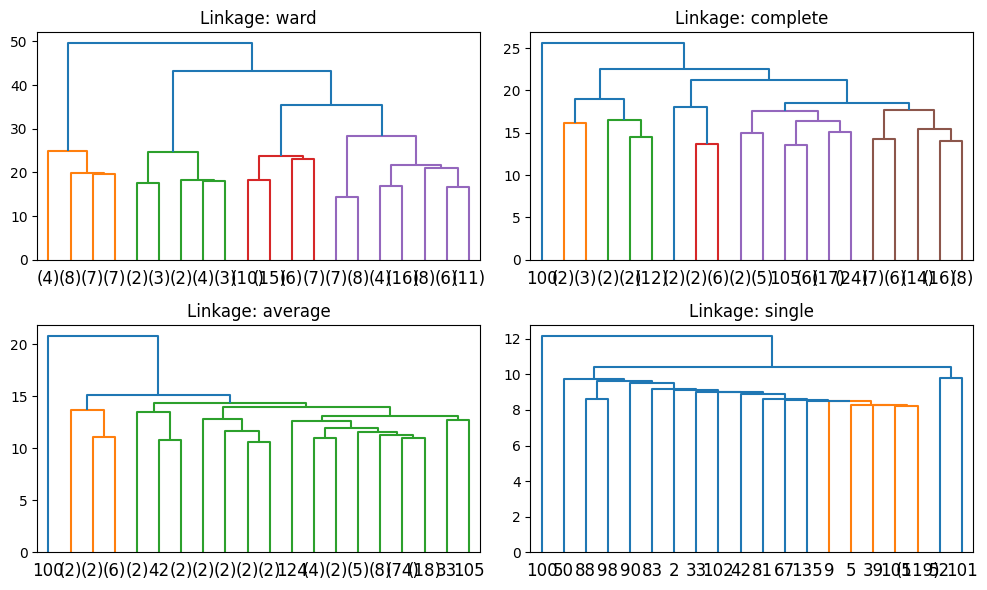

In [11]:
methods = ['ward', 'complete', 'average', 'single']

fig, axes = plt.subplots(2, 2, figsize=(10, 6))
for ax, m in zip(axes.ravel(), methods):
    dendrogram(linkage(Z, m), truncate_mode='lastp', p=20, ax=ax)
    ax.set_title(f'Linkage: {m}')
plt.tight_layout(); plt.show()

for m in methods:
    labels[f'Agglo-{m}'] = AgglomerativeClustering(K, linkage=m).fit_predict(Z)

## Evaluation metrics

In [12]:
rows = []
for name, l in labels.items():
    rows.append({'Algorithm': name,
                 'Silhouette': silhouette_score(Z, l),
                 'Davies-Bouldin': davies_bouldin_score(Z, l),
                 'Calinski-Harabasz': calinski_harabasz_score(Z, l),
                 'ARI (vs true)': adjusted_rand_score(y_true, l)})
pd.DataFrame(rows).set_index('Algorithm').round(3)

,Silhouette,Davies-Bouldin,Calinski-Harabasz,ARI (vs true)
Algorithm,,,,
KMeans,0.165,2.117,21.356,0.224
Agglo-ward,0.163,2.020,18.535,0.117
Agglo-complete,0.428,0.424,5.033,0.000
Agglo-average,0.428,0.424,5.033,0.000
Agglo-single,0.428,0.424,5.033,0.000


## PCA 2D scatter

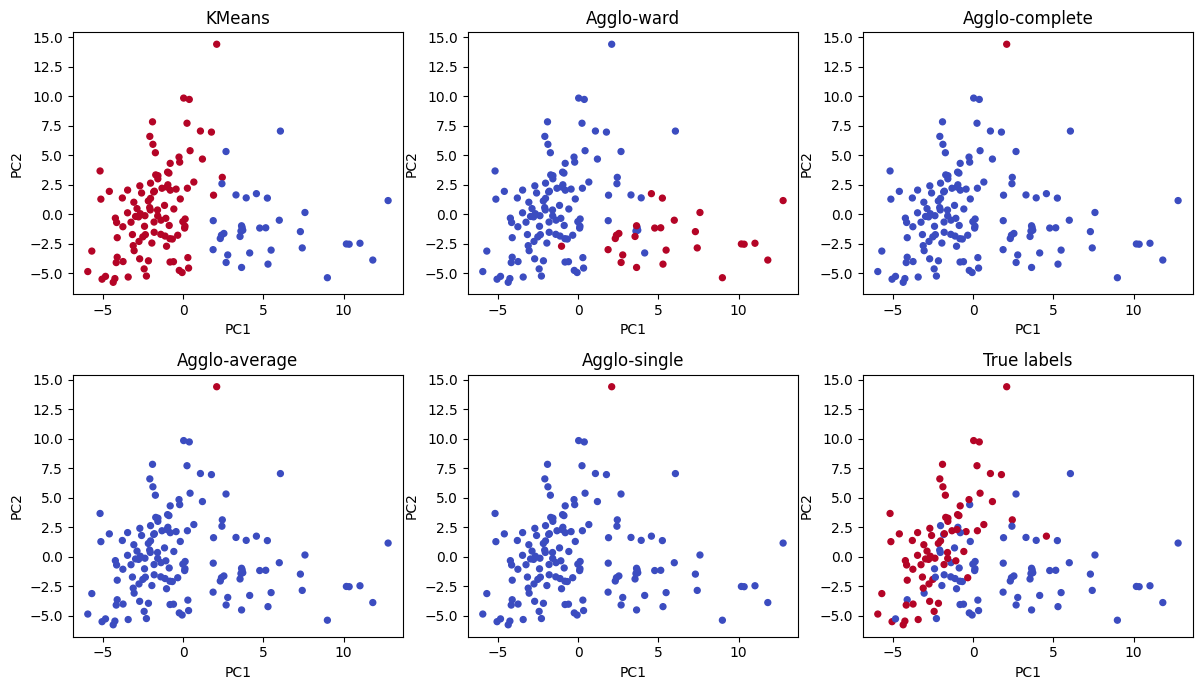

In [13]:
Z2 = PCA(2, random_state=0).fit_transform(Fs)
panels = {**labels, 'True labels': y_true}

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, (name, l) in zip(axes.ravel(), panels.items()):
    ax.scatter(Z2[:, 0], Z2[:, 1], c=l, cmap='coolwarm', s=18)
    ax.set_title(name); ax.set_xlabel('PC1'); ax.set_ylabel('PC2')
plt.tight_layout(); plt.show()

## t-SNE

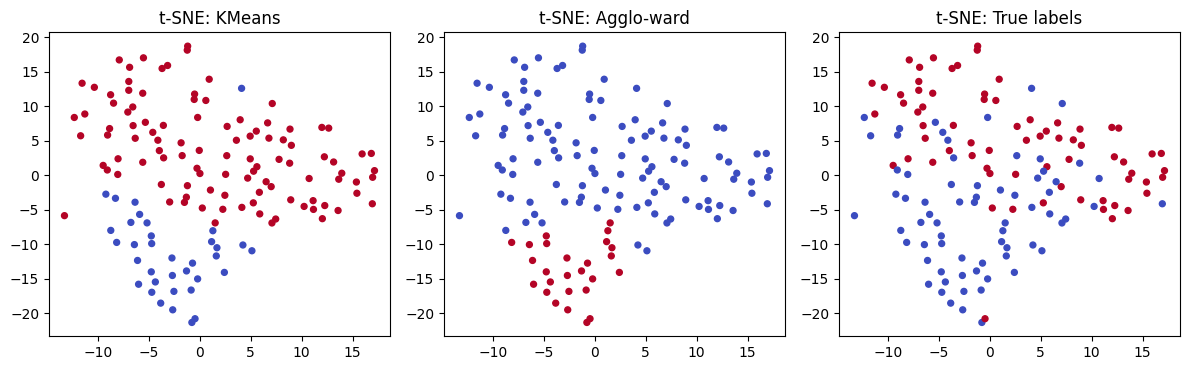

In [14]:
T = TSNE(2, perplexity=15, random_state=0).fit_transform(Z)
panels = {'KMeans': labels['KMeans'], 'Agglo-ward': labels['Agglo-ward'], 'True labels': y_true}

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, (name, l) in zip(axes, panels.items()):
    ax.scatter(T[:, 0], T[:, 1], c=l, cmap='coolwarm', s=18)
    ax.set_title(f't-SNE: {name}')
plt.tight_layout(); plt.show()